# ۳. بررسی چند موج واقعی

این نوت‌بوک آموزش نمی‌دهد. چهار ضبط را از /content/aurora_waveforms می‌خواند، فیلترهای بخش II-B را اعمال می‌کند، و ضربان را با ستون‌های رسمی 
eatures.tsv مقایسه می‌کند.

آشکارساز QRS نسخهٔ تغییریافتهٔ Pan-Tompkins مقاله نیست. آن الگوریتم در مخزن رسمی نیست، پس آشکارساز این نوت‌بوک [DECISION] است و فقط برای مقایسهٔ عددی به کار می‌رود. نقطهٔ رسیدن موج نبض هم در مقاله مشخص نشده؛ چند نامزد گزارش می‌شود و هیچ‌کدام تعریف نویسنده اعلام نمی‌شود.


In [1]:
import base64
from pathlib import Path
root = Path('/content/aurorabp_reproduction')
(root / 'src').mkdir(parents=True, exist_ok=True)
(root / 'src' / '__init__.py').write_text("\"\"\"Aurora-BP reproduction package. Author settings are not inferred silently.\"\"\"\n\n__version__ = \"0.1.0\"\n", encoding='utf-8')
(root / 'src' / 'filters.py').write_bytes(base64.b64decode("IiIiRmlsdGVycyBmcm9tIE1pZWxvc3p5ayBldCBhbC4sIElFRUUgSkJISSAyMDIyLCBTZWN0aW9uIElJLUIuCgpTb3VyY2UgbGFiZWxzIGluIHRoaXMgbW9kdWxlOgotIFtQQVBFUl0gc3RhdGVkIGJ5IE1pZWxvc3p5ayBldCBhbC4KLSBbREVDSVNJT05dIG5vdCBzdGF0ZWQgYnkgdGhlIHBhcGVyIG9yIHRoZSBvZmZpY2lhbCByZXBvc2l0b3J5LgoKVGhlIG9mZmljaWFsIHdhdmVmb3JtIG5vdGVib29rIHVzZXMgYSBkaWZmZXJlbnQgQnV0dGVyd29ydGggYmFuZHBhc3MgYW5kCmxhYmVscyB0aGF0IGZ1bmN0aW9uIGFkIGhvYy4gVGhvc2UgY29lZmZpY2llbnRzIGFyZSBub3QgdXNlZCBoZXJlLgoiIiIKCmZyb20gX19mdXR1cmVfXyBpbXBvcnQgYW5ub3RhdGlvbnMKCmZyb20gZnVuY3Rvb2xzIGltcG9ydCBscnVfY2FjaGUKZnJvbSB0eXBpbmcgaW1wb3J0IERpY3QKCmltcG9ydCBudW1weSBhcyBucApmcm9tIHNjaXB5IGltcG9ydCBzaWduYWwKCiMgW0RFQ0lTSU9OXSBSZWxlYXNlZCBmaWxlcyBhcmUgcmVzYW1wbGVkIHRvIDUwMCBIei4gVGhlIHBhcGVyIGRvZXMgbm90CiMgc3RhdGUgdGhlIHNhbXBsaW5nIHJhdGUgdXNlZCB0byBkZXNpZ24gdGhlIE1hdGxhYiBmaWx0ZXJzLgpSRUxFQVNFRF9GU19IWiA9IDUwMC4wCgojIFtERUNJU0lPTl0gWmVyby1waGFzZSBmaWx0ZXJpbmcuIFRoZSBwYXBlciBkb2VzIG5vdCBzYXkgY2F1c2FsIG9yIHplcm8tcGhhc2UuCiMgc29zZmlsdGZpbHQgc3F1YXJlcyB0aGUgbWFnbml0dWRlIHJlc3BvbnNlLCBzbyBwYXNzYmFuZCByaXBwbGUgaW4gZEIgZG91Ymxlcy4KWkVST19QSEFTRSA9IFRydWUKCgpkZWYgX2FzX2Zsb2F0KHg6IG5wLm5kYXJyYXkpIC0+IG5wLm5kYXJyYXk6CiAgICB2YWx1ZXMgPSBucC5hc2FycmF5KHgsIGR0eXBlPWZsb2F0KQogICAgaWYgdmFsdWVzLm5kaW0gIT0gMToKICAgICAgICByYWlzZSBWYWx1ZUVycm9yKCJFYWNoIHdhdmVmb3JtIG11c3QgYmUgYSBvbmUtZGltZW5zaW9uYWwgYXJyYXkuIikKICAgIHJldHVybiB2YWx1ZXMKCgpkZWYgYXBwbHlfc29zKHNvczogbnAubmRhcnJheSwgdmFsdWVzOiBucC5uZGFycmF5LCB6ZXJvX3BoYXNlOiBib29sID0gWkVST19QSEFTRSkgLT4gbnAubmRhcnJheToKICAgICIiIkFwcGx5IGFuIElJUiBmaWx0ZXIgaW4gc2Vjb25kLW9yZGVyIHNlY3Rpb25zLiIiIgogICAgZGF0YSA9IF9hc19mbG9hdCh2YWx1ZXMpCiAgICBpZiBkYXRhLnNpemUgPT0gMCBvciBub3QgbnAuaXNmaW5pdGUoZGF0YSkuYW55KCk6CiAgICAgICAgcmV0dXJuIG5wLmZ1bGwoZGF0YS5zaGFwZSwgbnAubmFuKQogICAgZmluaXRlID0gbnAuaXNmaW5pdGUoZGF0YSkKICAgIGlmIG5vdCBmaW5pdGUuYWxsKCk6CiAgICAgICAgIyBbREVDSVNJT05dIGludGVycG9sYXRlIG9ubHkgaW50ZXJuYWwgaXNvbGF0ZWQgZ2Fwcy4gRWRnZXMgc3RheSBOYU4uCiAgICAgICAgaW5kZXggPSBucC5hcmFuZ2UoZGF0YS5zaXplKQogICAgICAgIGRhdGEgPSBkYXRhLmNvcHkoKQogICAgICAgIGRhdGFbfmZpbml0ZV0gPSBucC5pbnRlcnAoaW5kZXhbfmZpbml0ZV0sIGluZGV4W2Zpbml0ZV0sIGRhdGFbZmluaXRlXSkKICAgIGlmIHplcm9fcGhhc2U6CiAgICAgICAgcmV0dXJuIHNpZ25hbC5zb3NmaWx0ZmlsdChzb3MsIGRhdGEpCiAgICByZXR1cm4gc2lnbmFsLnNvc2ZpbHQoc29zLCBkYXRhKQoKCmRlZiBhcHBseV9maXIoY29lZmZpY2llbnRzOiBucC5uZGFycmF5LCB2YWx1ZXM6IG5wLm5kYXJyYXksIHplcm9fcGhhc2U6IGJvb2wgPSBaRVJPX1BIQVNFKSAtPiBucC5uZGFycmF5OgogICAgIiIiQXBwbHkgYW4gRklSIGZpbHRlci4gWmVyby1waGFzZSB1c2VzIGZvcndhcmQtYmFja3dhcmQgZmlsdGVyaW5nLiIiIgogICAgZGF0YSA9IF9hc19mbG9hdCh2YWx1ZXMpCiAgICBpZiBkYXRhLnNpemUgPT0gMCBvciBub3QgbnAuaXNmaW5pdGUoZGF0YSkuYW55KCk6CiAgICAgICAgcmV0dXJuIG5wLmZ1bGwoZGF0YS5zaGFwZSwgbnAubmFuKQogICAgaWYgemVyb19waGFzZToKICAgICAgICByZXR1cm4gc2lnbmFsLmZpbHRmaWx0KGNvZWZmaWNpZW50cywgWzEuMF0sIGRhdGEpCiAgICByZXR1cm4gc2lnbmFsLmxmaWx0ZXIoY29lZmZpY2llbnRzLCBbMS4wXSwgZGF0YSkKCgpAbHJ1X2NhY2hlKG1heHNpemU9NCkKZGVmIGRlc2lnbl9lY2coZnM6IGZsb2F0ID0gUkVMRUFTRURfRlNfSFopIC0+IERpY3Rbc3RyLCBucC5uZGFycmF5XToKICAgICIiIkVDRzogREMgYmxvY2ssIGVsbGlwdGljIGxvd3Bhc3MsIENoZWJ5c2hldiBUeXBlIEkgbm90Y2guIFtQQVBFUl0KCiAgICBVbnNwZWNpZmllZCBwaWVjZXMsIGFsbCBbREVDSVNJT05dOgogICAgLSBEQyBibG9jayBpcyBhIGZpcnN0LW9yZGVyIEJ1dHRlcndvcnRoIGhpZ2hwYXNzIGF0IDAuMSBIei4KICAgIC0gRWxsaXB0aWMgc3RvcGJhbmQgYXR0ZW51YXRpb24gaXMgNDAgZEIuIEF0IHRoZSBwYXBlcidzIGVkZ2VzIGFuZAogICAgICAwLjEgZEIgcmlwcGxlLCBlbGxpcG9yZCByZXR1cm5zIG9yZGVyIDcgb25seSBuZWFyIHRoaXMgYXR0ZW51YXRpb24uCiAgICAtIE5vdGNoIFEgaXMgY2VudGVyL2JhbmR3aWR0aCwgc28gdGhlIG9yZGVyLTYgYmFuZHN0b3Agc3BhbnMgNTDigJM3MCBIei4KICAgICAgc2NpcHkuc2lnbmFsLmNoZWJ5MSB1c2VzIE49MyBmb3IgYSA2dGgtb3JkZXIgYmFuZHN0b3AuCiAgICAiIiIKICAgIGRjID0gc2lnbmFsLmJ1dHRlcigxLCAwLjEsIGJ0eXBlPSJoaWdocGFzcyIsIG91dHB1dD0ic29zIiwgZnM9ZnMpCiAgICBsb3dwYXNzID0gc2lnbmFsLmVsbGlwKDcsIDAuMSwgNDAuMCwgNDAuMCwgYnR5cGU9Imxvd3Bhc3MiLCBvdXRwdXQ9InNvcyIsIGZzPWZzKQogICAgYmFuZHdpZHRoID0gNjAuMCAvIDMuMAogICAgZWRnZXMgPSAoNjAuMCAtIGJhbmR3aWR0aCAvIDIuMCwgNjAuMCArIGJhbmR3aWR0aCAvIDIuMCkKICAgIG5vdGNoID0gc2lnbmFsLmNoZWJ5MSgzLCAwLjEsIGVkZ2VzLCBidHlwZT0iYmFuZHN0b3AiLCBvdXRwdXQ9InNvcyIsIGZzPWZzKQogICAgcmV0dXJuIHsiZGMiOiBkYywgImxvd3Bhc3MiOiBsb3dwYXNzLCAibm90Y2giOiBub3RjaH0KCgpAbHJ1X2NhY2hlKG1heHNpemU9NCkKZGVmIGRlc2lnbl9wcGcoZnM6IGZsb2F0ID0gUkVMRUFTRURfRlNfSFopIC0+IERpY3Rbc3RyLCBucC5uZGFycmF5XToKICAgICIiIlBQRzogQnV0dGVyd29ydGggaGlnaHBhc3MgYW5kIGVxdWlyaXBwbGUgbG93cGFzcy4gW1BBUEVSXQoKICAgIFRoZSBlcXVpcmlwcGxlIG9yZGVyIGlzIG5vdCBzdGF0ZWQuIDUyMSB0YXBzIGlzIHRoZSBzaG9ydGVzdCBvZGQgbGVuZ3RoCiAgICBmb3VuZCB3aXRoIHNjaXB5LnNpZ25hbC5yZW1leiBhdCA1MDAgSHogdGhhdCBtZWV0cyAxIGRCIGFuZCA2MCBkQiBpbiBhCiAgICBzaW5nbGUgcGFzcy4gW0RFQ0lTSU9OXQogICAgIiIiCiAgICBpZiBhYnMoZnMgLSBSRUxFQVNFRF9GU19IWikgPiAxZS02OgogICAgICAgIHJhaXNlIFZhbHVlRXJyb3IoIlRoZSBjYWNoZWQgZXF1aXJpcHBsZSBsZW5ndGggaXMgdmFsaWQgb25seSBhdCA1MDAgSHouIFJlZGVzaWduIGl0IGZvciBhbm90aGVyIHJhdGUuIikKICAgIGhpZ2hwYXNzID0gc2lnbmFsLmJ1dHRlcig0LCAwLjI1LCBidHlwZT0iaGlnaHBhc3MiLCBvdXRwdXQ9InNvcyIsIGZzPWZzKQogICAgcmlwcGxlX2RiID0gMS4wCiAgICBhdHRlbnVhdGlvbl9kYiA9IDYwLjAKICAgIGRldmlhdGlvbl9wYXNzID0gKDEwICoqIChyaXBwbGVfZGIgLyAyMC4wKSAtIDEuMCkgLyAoMTAgKiogKHJpcHBsZV9kYiAvIDIwLjApICsgMS4wKQogICAgZGV2aWF0aW9uX3N0b3AgPSAxMCAqKiAoLWF0dGVudWF0aW9uX2RiIC8gMjAuMCkKICAgIGxvd3Bhc3MgPSBzaWduYWwucmVtZXooCiAgICAgICAgNTIxLAogICAgICAgIFswLjAsIDEwLjAsIDEyLjAsIGZzIC8gMi4wXSwKICAgICAgICBbMS4wLCAwLjBdLAogICAgICAgIHdlaWdodD1bMS4wIC8gZGV2aWF0aW9uX3Bhc3MsIDEuMCAvIGRldmlhdGlvbl9zdG9wXSwKICAgICAgICBmcz1mcywKICAgICAgICBtYXhpdGVyPTUwLAogICAgKQogICAgcmV0dXJuIHsiaGlnaHBhc3MiOiBoaWdocGFzcywgImxvd3Bhc3MiOiBsb3dwYXNzfQoKCkBscnVfY2FjaGUobWF4c2l6ZT00KQpkZWYgZGVzaWduX3Rvbm9tZXRyeShmczogZmxvYXQgPSBSRUxFQVNFRF9GU19IWikgLT4gRGljdFtzdHIsIG5wLm5kYXJyYXldOgogICAgIiIiVG9ub21ldHJ5OiBlbGxpcHRpYyBoaWdocGFzcyBhbmQgN3RoLW9yZGVyIGVsbGlwdGljIGxvd3Bhc3MuIFtQQVBFUl0KCiAgICBbREVDSVNJT05dIEhpZ2hwYXNzIG9yZGVyIGlzIDYsIHRoZSBtaW5pbXVtIHJldHVybmVkIGJ5IGVsbGlwb3JkIGZvciB0aGUKICAgIHN0YXRlZCBlZGdlcywgMSBkQiByaXBwbGUsIGFuZCA2MCBkQiBhdHRlbnVhdGlvbi4KICAgIFtERUNJU0lPTl0gTG93cGFzcyBzdG9wYmFuZCBhdHRlbnVhdGlvbiBpcyA0MCBkQiBzbyB0aGF0IG9yZGVyIDcgaXMKICAgIGNvbnNpc3RlbnQgd2l0aCBhIDIyIEh6IHBhc3NiYW5kIGVkZ2UgYW5kIGEgMjYgSHogc3RvcGJhbmQgZWRnZS4KICAgICIiIgogICAgaGlnaHBhc3MgPSBzaWduYWwuZWxsaXAoNiwgMS4wLCA2MC4wLCAwLjMsIGJ0eXBlPSJoaWdocGFzcyIsIG91dHB1dD0ic29zIiwgZnM9ZnMpCiAgICBsb3dwYXNzID0gc2lnbmFsLmVsbGlwKDcsIDAuMSwgNDAuMCwgMjIuMCwgYnR5cGU9Imxvd3Bhc3MiLCBvdXRwdXQ9InNvcyIsIGZzPWZzKQogICAgcmV0dXJuIHsiaGlnaHBhc3MiOiBoaWdocGFzcywgImxvd3Bhc3MiOiBsb3dwYXNzfQoKCmRlZiBmaWx0ZXJfZWNnKHZhbHVlczogbnAubmRhcnJheSwgZnM6IGZsb2F0ID0gUkVMRUFTRURfRlNfSFosIHplcm9fcGhhc2U6IGJvb2wgPSBaRVJPX1BIQVNFKSAtPiBucC5uZGFycmF5OgogICAgIiIiQXBwbHkgdGhlIEVDRyBmaWx0ZXJzIGluIHRoZSBvcmRlciBsaXN0ZWQgaW4gU2VjdGlvbiBJSS1CLiIiIgogICAgc3RhZ2VzID0gZGVzaWduX2VjZyhmcykKICAgIG91dHB1dCA9IGFwcGx5X3NvcyhzdGFnZXNbImRjIl0sIHZhbHVlcywgemVyb19waGFzZT16ZXJvX3BoYXNlKQogICAgb3V0cHV0ID0gYXBwbHlfc29zKHN0YWdlc1sibG93cGFzcyJdLCBvdXRwdXQsIHplcm9fcGhhc2U9emVyb19waGFzZSkKICAgIHJldHVybiBhcHBseV9zb3Moc3RhZ2VzWyJub3RjaCJdLCBvdXRwdXQsIHplcm9fcGhhc2U9emVyb19waGFzZSkKCgpkZWYgZmlsdGVyX3BwZyh2YWx1ZXM6IG5wLm5kYXJyYXksIGZzOiBmbG9hdCA9IFJFTEVBU0VEX0ZTX0haLCB6ZXJvX3BoYXNlOiBib29sID0gWkVST19QSEFTRSkgLT4gbnAubmRhcnJheToKICAgICIiIkFwcGx5IHRoZSBQUEcgZmlsdGVycyBpbiB0aGUgb3JkZXIgbGlzdGVkIGluIFNlY3Rpb24gSUktQi4iIiIKICAgIHN0YWdlcyA9IGRlc2lnbl9wcGcoZnMpCiAgICBvdXRwdXQgPSBhcHBseV9zb3Moc3RhZ2VzWyJoaWdocGFzcyJdLCB2YWx1ZXMsIHplcm9fcGhhc2U9emVyb19waGFzZSkKICAgIHJldHVybiBhcHBseV9maXIoc3RhZ2VzWyJsb3dwYXNzIl0sIG91dHB1dCwgemVyb19waGFzZT16ZXJvX3BoYXNlKQoKCmRlZiBmaWx0ZXJfdG9ub21ldHJ5KHZhbHVlczogbnAubmRhcnJheSwgZnM6IGZsb2F0ID0gUkVMRUFTRURfRlNfSFosIHplcm9fcGhhc2U6IGJvb2wgPSBaRVJPX1BIQVNFKSAtPiBucC5uZGFycmF5OgogICAgIiIiQXBwbHkgdGhlIHRvbm9tZXRyeSBmaWx0ZXJzIGluIHRoZSBvcmRlciBsaXN0ZWQgaW4gU2VjdGlvbiBJSS1CLiIiIgogICAgc3RhZ2VzID0gZGVzaWduX3Rvbm9tZXRyeShmcykKICAgIG91dHB1dCA9IGFwcGx5X3NvcyhzdGFnZXNbImhpZ2hwYXNzIl0sIHZhbHVlcywgemVyb19waGFzZT16ZXJvX3BoYXNlKQogICAgcmV0dXJuIGFwcGx5X3NvcyhzdGFnZXNbImxvd3Bhc3MiXSwgb3V0cHV0LCB6ZXJvX3BoYXNlPXplcm9fcGhhc2UpCgoKZGVmIGdhaW5fZGJfYXQoa2luZDogc3RyLCBzdGFnZTogc3RyLCB0YXJnZXRfaHo6IGZsb2F0LCBmczogZmxvYXQgPSBSRUxFQVNFRF9GU19IWikgLT4gZmxvYXQ6CiAgICAiIiJHYWluIGF0IG9uZSBleGFjdCBmcmVxdWVuY3ksIG5vdCBhdCB0aGUgbmVhcmVzdCBGRlQgYmluLiIiIgogICAgaWYga2luZCA9PSAiZWNnIjoKICAgICAgICBjb2VmZmljaWVudHMgPSBkZXNpZ25fZWNnKGZzKVtzdGFnZV0KICAgIGVsaWYga2luZCA9PSAicHBnIjoKICAgICAgICBjb2VmZmljaWVudHMgPSBkZXNpZ25fcHBnKGZzKVtzdGFnZV0KICAgIGVsaWYga2luZCA9PSAidG9ub21ldHJ5IjoKICAgICAgICBjb2VmZmljaWVudHMgPSBkZXNpZ25fdG9ub21ldHJ5KGZzKVtzdGFnZV0KICAgIGVsc2U6CiAgICAgICAgcmFpc2UgVmFsdWVFcnJvcihmIlVua25vd24gZmlsdGVyIGdyb3VwOiB7a2luZH0iKQogICAgaWYgY29lZmZpY2llbnRzLm5kaW0gPT0gMToKICAgICAgICBfLCByZXNwb25zZSA9IHNpZ25hbC5mcmVxeihjb2VmZmljaWVudHMsIHdvck49W3RhcmdldF9oel0sIGZzPWZzKQogICAgZWxzZToKICAgICAgICBfLCByZXNwb25zZSA9IHNpZ25hbC5zb3NmcmVxeihjb2VmZmljaWVudHMsIHdvck49W3RhcmdldF9oel0sIGZzPWZzKQogICAgcmV0dXJuIGZsb2F0KDIwLjAgKiBucC5sb2cxMChtYXgoYWJzKHJlc3BvbnNlWzBdKSwgMWUtMTIpKSkKCgpkZWYgc3RhZ2VfcmVzcG9uc2Uoa2luZDogc3RyLCBzdGFnZTogc3RyLCBmczogZmxvYXQgPSBSRUxFQVNFRF9GU19IWiwgd29yX246IGludCA9IDE2Mzg0KSAtPiBEaWN0W3N0ciwgbnAubmRhcnJheV06CiAgICAiIiJGcmVxdWVuY3kgcmVzcG9uc2Ugb2Ygb25lIGRlc2lnbmVkIHN0YWdlLCBzaW5nbGUgcGFzcy4iIiIKICAgIGlmIGtpbmQgPT0gImVjZyI6CiAgICAgICAgY29lZmZpY2llbnRzID0gZGVzaWduX2VjZyhmcylbc3RhZ2VdCiAgICBlbGlmIGtpbmQgPT0gInBwZyI6CiAgICAgICAgY29lZmZpY2llbnRzID0gZGVzaWduX3BwZyhmcylbc3RhZ2VdCiAgICBlbGlmIGtpbmQgPT0gInRvbm9tZXRyeSI6CiAgICAgICAgY29lZmZpY2llbnRzID0gZGVzaWduX3Rvbm9tZXRyeShmcylbc3RhZ2VdCiAgICBlbHNlOgogICAgICAgIHJhaXNlIFZhbHVlRXJyb3IoZiJVbmtub3duIGZpbHRlciBncm91cDoge2tpbmR9IikKICAgIGlmIGNvZWZmaWNpZW50cy5uZGltID09IDE6CiAgICAgICAgZnJlcXVlbmNpZXMsIHJlc3BvbnNlID0gc2lnbmFsLmZyZXF6KGNvZWZmaWNpZW50cywgd29yTj13b3JfbiwgZnM9ZnMpCiAgICBlbHNlOgogICAgICAgIGZyZXF1ZW5jaWVzLCByZXNwb25zZSA9IHNpZ25hbC5zb3NmcmVxeihjb2VmZmljaWVudHMsIHdvck49d29yX24sIGZzPWZzKQogICAgbWFnbml0dWRlX2RiID0gMjAuMCAqIG5wLmxvZzEwKG5wLm1heGltdW0obnAuYWJzKHJlc3BvbnNlKSwgMWUtMTIpKQogICAgcmV0dXJuIHsiaHoiOiBmcmVxdWVuY2llcywgImRiIjogbWFnbml0dWRlX2RifQoKCmRlZiBzcGVjaWZpY2F0aW9uX2NoZWNrKGZzOiBmbG9hdCA9IFJFTEVBU0VEX0ZTX0haKSAtPiBEaWN0W3N0ciwgZmxvYXRdOgogICAgIiIiTWVhc3VyZSBzaW5nbGUtcGFzcyBnYWluIGF0IHRoZSBwYXBlcidzIHN0YXRlZCBlZGdlcy4KCiAgICBQYXNzYmFuZCBlbGxpcHRpYyBhbmQgQ2hlYnlzaGV2IGVkZ2VzIGFyZSB0aGUgLXJpcHBsZSBwb2ludHMsIG5vdCB0aGUKICAgIC0zIGRCIHBvaW50cy4gQnV0dGVyd29ydGggZWRnZXMgYXJlIHRoZSAtMyBkQiBwb2ludHMuCiAgICAiIiIKICAgIHByb2JlcyA9IHsKICAgICAgICAiZWNnX2RjXzAuMWh6X2RiIjogKCJlY2ciLCAiZGMiLCAwLjEpLAogICAgICAgICJlY2dfbG93cGFzc180MGh6X2RiIjogKCJlY2ciLCAibG93cGFzcyIsIDQwLjApLAogICAgICAgICJlY2dfbG93cGFzc180NWh6X2RiIjogKCJlY2ciLCAibG93cGFzcyIsIDQ1LjApLAogICAgICAgICJlY2dfbm90Y2hfNTBoel9kYiI6ICgiZWNnIiwgIm5vdGNoIiwgNTAuMCksCiAgICAgICAgImVjZ19ub3RjaF82MGh6X2RiIjogKCJlY2ciLCAibm90Y2giLCA2MC4wKSwKICAgICAgICAiZWNnX25vdGNoXzcwaHpfZGIiOiAoImVjZyIsICJub3RjaCIsIDcwLjApLAogICAgICAgICJwcGdfaGlnaHBhc3NfMC4yNWh6X2RiIjogKCJwcGciLCAiaGlnaHBhc3MiLCAwLjI1KSwKICAgICAgICAicHBnX2xvd3Bhc3NfMTBoel9kYiI6ICgicHBnIiwgImxvd3Bhc3MiLCAxMC4wKSwKICAgICAgICAicHBnX2xvd3Bhc3NfMTJoel9kYiI6ICgicHBnIiwgImxvd3Bhc3MiLCAxMi4wKSwKICAgICAgICAidG9ub21ldHJ5X2hpZ2hwYXNzXzAuMmh6X2RiIjogKCJ0b25vbWV0cnkiLCAiaGlnaHBhc3MiLCAwLjIpLAogICAgICAgICJ0b25vbWV0cnlfaGlnaHBhc3NfMC4zaHpfZGIiOiAoInRvbm9tZXRyeSIsICJoaWdocGFzcyIsIDAuMyksCiAgICAgICAgInRvbm9tZXRyeV9sb3dwYXNzXzIyaHpfZGIiOiAoInRvbm9tZXRyeSIsICJsb3dwYXNzIiwgMjIuMCksCiAgICAgICAgInRvbm9tZXRyeV9sb3dwYXNzXzI2aHpfZGIiOiAoInRvbm9tZXRyeSIsICJsb3dwYXNzIiwgMjYuMCksCiAgICB9CiAgICByZXR1cm4ge25hbWU6IGdhaW5fZGJfYXQoa2luZCwgc3RhZ2UsIGh6LCBmcz1mcykgZm9yIG5hbWUsIChraW5kLCBzdGFnZSwgaHopIGluIHByb2Jlcy5pdGVtcygpfQo="))
print(root / 'src' / 'filters.py')


/content/aurorabp_reproduction/src/filters.py


In [2]:
import sys
from pathlib import Path
sys.path.insert(0, '/content/aurorabp_reproduction')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.filters import filter_ecg, filter_ppg, filter_tonometry

ROOT = Path('/content/aurora_waveforms')
FS = 500.0
if not ROOT.is_dir():
    raise FileNotFoundError(ROOT)

def pick(folder: Path, token: str):
    matches = sorted(p for p in folder.glob('*.tsv') if token in p.name)
    return matches[0] if matches else None

chosen = [
    pick(ROOT / 'measurements_auscultatory' / 'a000', 'initial.Calibration'),
    pick(ROOT / 'measurements_auscultatory' / 'a000', '.return.'),
    pick(ROOT / 'measurements_oscillometric' / 'o000', 'ambulatory.measurement_23'),
    pick(ROOT / 'measurements_oscillometric' / 'o000', '.initial.'),
]
chosen = [path for path in chosen if path is not None]
for path in chosen:
    print(path.relative_to(ROOT))
if len(chosen) < 3:
    raise RuntimeError('فایل نمونه به اندازهٔ کافی پیدا نشد.')


measurements_auscultatory/a000/a000.initial.Calibration_start_1.tsv
measurements_auscultatory/a000/a000.return.Temporal_challenge_start_1.tsv
measurements_oscillometric/o000/o000.ambulatory.measurement_23.tsv
measurements_oscillometric/o000/o000.initial.Cool_down_1.tsv


In [3]:
def load_wave(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path, sep='\t')
    dt = np.diff(frame['t'].to_numpy(dtype=float))
    dt = dt[np.isfinite(dt) & (dt > 0)]
    rate = float(1.0 / np.median(dt)) if dt.size else float('nan')
    print(f'{path.name}: n={len(frame)}  نرخ={rate:.2f}  ستون={list(frame.columns)}')
    return frame

waves = {path: load_wave(path) for path in chosen}

def filtered_channels(frame: pd.DataFrame):
    return {
        'ekg': filter_ecg(frame['ekg'].to_numpy(dtype=float), fs=FS),
        'optical': filter_ppg(frame['optical'].to_numpy(dtype=float), fs=FS),
        'pressure': filter_tonometry(frame['pressure'].to_numpy(dtype=float), fs=FS),
    }

filtered = {path: filtered_channels(frame) for path, frame in waves.items()}
print('فیلتر چهار ضبط تمام شد.')


a000.initial.Calibration_start_1.tsv: n=9275  نرخ=500.00  ستون=['t', 'ekg', 'optical', 'pressure', 'accel_x', 'accel_y', 'accel_z']
a000.return.Temporal_challenge_start_1.tsv: n=10580  نرخ=500.00  ستون=['t', 'ekg', 'optical', 'pressure', 'accel_x', 'accel_y', 'accel_z']
o000.ambulatory.measurement_23.tsv: n=7501  نرخ=500.00  ستون=['t', 'ekg', 'optical', 'pressure', 'accel_x', 'accel_y', 'accel_z']
o000.initial.Cool_down_1.tsv: n=15000  نرخ=500.00  ستون=['t', 'ekg', 'optical', 'pressure', 'accel_x', 'accel_y', 'accel_z']
فیلتر چهار ضبط تمام شد.


In [4]:
# [DECISION] این آشکارساز Pan-Tompkins نیست.
# قله با فاصلهٔ حداقل ۰٫۳ ثانیه و برجستگی نسبی پیدا می‌شود.
# ضربان برابر ۶۰ تقسیم بر میانهٔ فاصلهٔ قله‌ها، بر حسب bpm است.

def peaks_of(values: np.ndarray, fs: float = FS) -> np.ndarray:
    finite = np.isfinite(values)
    if finite.sum() < int(fs):
        return np.array([], dtype=int)
    series = np.where(finite, values, np.nanmedian(values[finite]))
    scale = np.nanstd(series)
    if not np.isfinite(scale) or scale == 0:
        return np.array([], dtype=int)
    from scipy.signal import find_peaks
    index, _ = find_peaks(series, distance=int(0.30 * fs), prominence=0.5 * scale)
    return index

def rate_bpm(index: np.ndarray, fs: float = FS):
    if index.size < 3:
        return float('nan'), 0
    intervals = np.diff(index) / fs
    intervals = intervals[(intervals >= 0.30) & (intervals <= 1.50)]
    if intervals.size == 0:
        return float('nan'), 0
    return float(60.0 / np.median(intervals)), int(intervals.size)

def pulse_delays_ms(qrs: np.ndarray, pulse: np.ndarray, fs: float = FS):
    delays = []
    for beat in qrs:
        later = pulse[(pulse > beat + int(0.08 * fs)) & (pulse < beat + int(0.60 * fs))]
        if later.size:
            delays.append((later[0] - beat) / fs * 1000.0)
    if not delays:
        return float('nan')
    return float(np.median(delays))

rows = []
for path, channels in filtered.items():
    qrs = peaks_of(channels['ekg'])
    optical = peaks_of(channels['optical'])
    pressure = peaks_of(channels['pressure'])
    hr_ekg, n_ekg = rate_bpm(qrs)
    hr_optical, n_optical = rate_bpm(optical)
    hr_pressure, n_pressure = rate_bpm(pressure)
    parts = path.stem.split('.')
    rows.append({
        'file': path.name,
        'participant': parts[0],
        'phase': parts[1] if len(parts) > 1 else '',
        'measurement': '.'.join(parts[2:]) if len(parts) > 2 else path.stem,
        'hr_ekg_decision': hr_ekg,
        'hr_optical_decision': hr_optical,
        'hr_pressure_decision': hr_pressure,
        'n_ekg': n_ekg,
        'delay_optical_peak_ms': pulse_delays_ms(qrs, optical),
        'delay_pressure_peak_ms': pulse_delays_ms(qrs, pressure),
    })
spot = pd.DataFrame(rows)
spot


,file,participant,phase,measurement,hr_ekg_decision,hr_optical_decision,hr_pressure_decision,n_ekg,delay_optical_peak_ms,delay_pressure_peak_ms
0,a000.initial.Calibration_start_1.tsv,a000,initial,Calibration_start_1,71.428571,70.921986,70.921986,21,578.0,340.0
1,a000.return.Temporal_challenge_start_1.tsv,a000,return,Temporal_challenge_start_1,72.289157,71.599045,72.463768,25,564.0,302.0
2,o000.ambulatory.measurement_23.tsv,o000,ambulatory,measurement_23,120.481928,88.365243,112.781955,27,412.0,308.0
3,o000.initial.Cool_down_1.tsv,o000,initial,Cool_down_1,88.495575,88.235294,NaN,45,384.0,304.0


In [5]:
features = pd.read_csv(ROOT / 'features.tsv', sep='\t')
print('ستون‌ها:', list(features.columns))
lower = {column.lower(): column for column in features.columns}
id_column = next((lower[name] for name in ('participant_id', 'pid', 'participant') if name in lower), None)
phase_column = lower.get('phase')
measurement_column = next((lower[name] for name in ('measurement', 'measurement_name', 'name') if name in lower), None)
official_columns = [column for column in features.columns if any(token in column.lower() for token in ('hr', 'rpat', 'pat', 'sbp', 'dbp'))]

compared = []
for row in spot.to_dict(orient='records'):
    matched = features
    if id_column:
        matched = matched[matched[id_column].astype(str) == row['participant']]
    if phase_column:
        matched = matched[matched[phase_column].astype(str) == row['phase']]
    if measurement_column:
        names = matched[measurement_column].astype(str)
        exact = matched[names == row['measurement']]
        matched = exact if len(exact) else matched[names.str.contains(row['measurement'], regex=False)]
    official = {}
    if len(matched) >= 1:
        source = matched.iloc[0]
        official = {column: source[column] for column in official_columns}
        official['official_rows_matched'] = int(len(matched))
    else:
        official['official_rows_matched'] = 0
    compared.append({**row, **official})

comparison = pd.DataFrame(compared)
comparison


ستون‌ها: ['pid', 'phase', 'measurement', 'date_time', 'sbp', 'dbp', 'baseline_sbp', 'baseline_dbp', 'delta_sbp', 'delta_dbp', 'arm_angle', 'motion_level', 'steps_last_five_mins', 'steps_last_thirty_mins', 'beat_length_ekg', 'hr_ekg', 'hrv_ekg', 'dpdt_optical', 'hr_optical', 'quality_optical', 'invpat_optical', 'rpat_optical', 'aix_pressure', 'dicrotic_notch_height_pressure', 'dpdt_pressure', 'ejection_duration_fraction_pressure', 'ejection_duration_pressure', 'hr_pressure', 'quality_pressure', 'rwat_pressure', 'sysrise_pressure', 'invpat_pressure', 'rpat_pressure', 'delta_arm_angle', 'delta_beat_length_ekg', 'delta_hr_ekg', 'delta_hrv_ekg', 'delta_dpdt_optical', 'delta_hr_optical', 'delta_quality_optical', 'delta_invpat_optical', 'delta_rpat_optical', 'delta_aix_pressure', 'delta_dicrotic_notch_height_pressure', 'delta_dpdt_pressure', 'delta_ejection_duration_fraction_pressure', 'delta_ejection_duration_pressure', 'delta_hr_pressure', 'delta_quality_pressure', 'delta_rwat_pressure', 'd

,file,participant,phase,measurement,hr_ekg_decision,hr_optical_decision,hr_pressure_decision,n_ekg,delay_optical_peak_ms,delay_pressure_peak_ms,official_rows_matched
0,a000.initial.Calibration_start_1.tsv,a000,initial,Calibration_start_1,71.428571,70.921986,70.921986,21,578.0,340.0,0
1,a000.return.Temporal_challenge_start_1.tsv,a000,return,Temporal_challenge_start_1,72.289157,71.599045,72.463768,25,564.0,302.0,0
2,o000.ambulatory.measurement_23.tsv,o000,ambulatory,measurement_23,120.481928,88.365243,112.781955,27,412.0,308.0,0
3,o000.initial.Cool_down_1.tsv,o000,initial,Cool_down_1,88.495575,88.235294,NaN,45,384.0,304.0,0


/content/aurorabp_outputs/figures/spotcheck_filtered.png


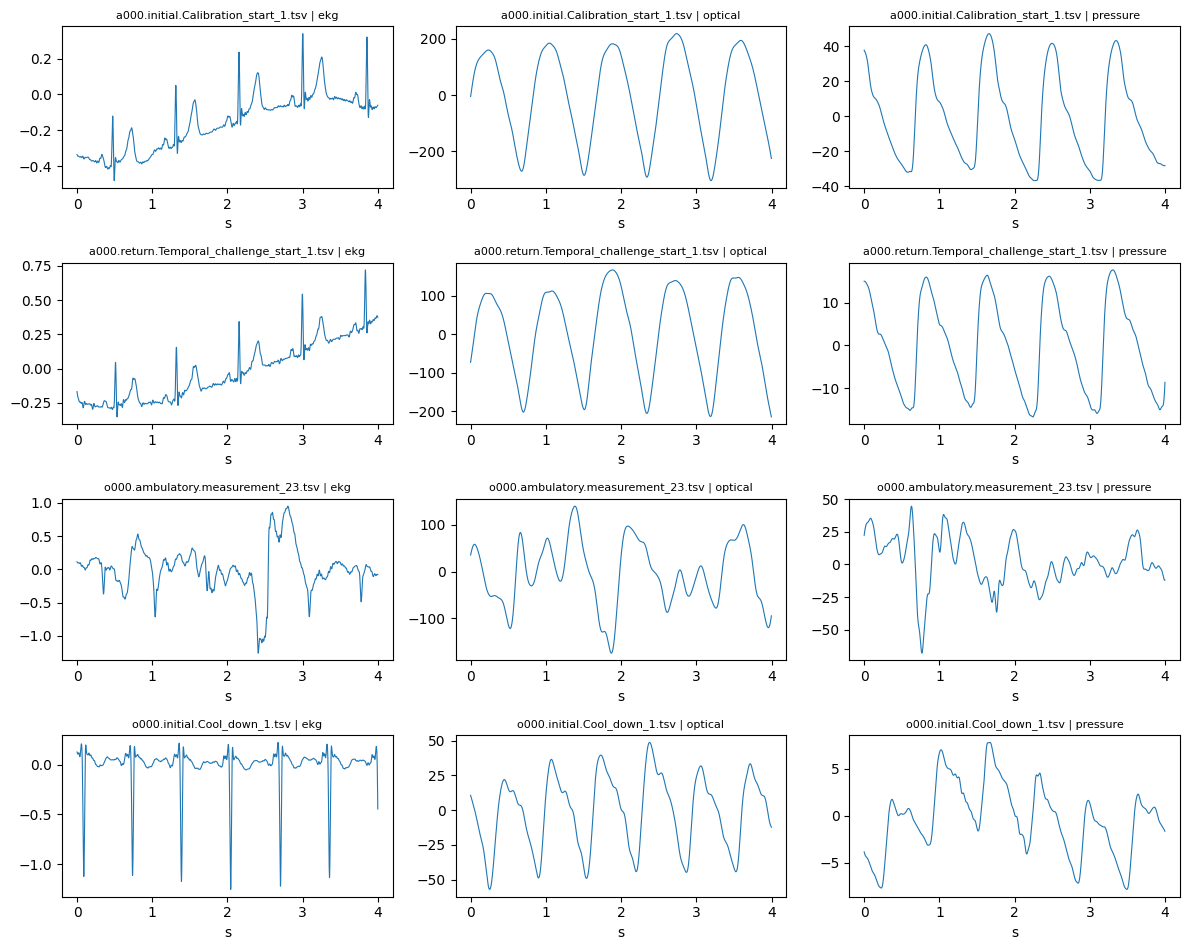

In [6]:
figure, axes = plt.subplots(len(filtered), 3, figsize=(12, 2.4 * len(filtered)), sharex=False)
if len(filtered) == 1:
    axes = np.array([axes])
for row, (path, channels) in enumerate(filtered.items()):
    frame = waves[path]
    start = max(0, int(len(frame) / 2 - 2 * FS))
    stop = min(len(frame), start + int(4 * FS))
    time = frame['t'].to_numpy(dtype=float)[start:stop]
    time = time - time[0]
    for column, name in enumerate(('ekg', 'optical', 'pressure')):
        ax = axes[row, column]
        ax.plot(time, channels[name][start:stop], lw=0.8)
        ax.set_title(f'{path.name} | {name}', fontsize=8)
        ax.set_xlabel('s')
figure.tight_layout()
out = Path('/content/aurorabp_outputs/figures')
out.mkdir(parents=True, exist_ok=True)
figure.savefig(out / 'spotcheck_filtered.png', dpi=120)
print(out / 'spotcheck_filtered.png')


In [ ]:
for pid in ("a000", "o000"):
    subset = features[features["pid"].astype(str) == pid]
    print(pid, "rows", len(subset))
    if len(subset):
        print(" phases", sorted(subset["phase"].astype(str).unique())[:12])
        print(" measurements", subset["measurement"].astype(str).head(12).tolist())
print("feature pids", features["pid"].nunique(), "example", features["pid"].astype(str).head(3).tolist())
